# Song et al. 2022 — Prostate Cancer · 03 Signatures
Publication panels for the three embryonic programs on the house-oriented manifold, plus the geography/gradient readout that certifies **Gate 2 GO / Gate 3 NA**.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 4574 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 71/81 genes present
pSom: 79/98 genes present
Crest: 102/104 genes present


### Geography + gradient → Gate 2 / Gate 3
The dominant inverse gradient (pSom↔Crest) with Crest terminal, and the sub-unity joint pSom&Crest-high enrichment (an inverse gradient, not a co-expression hub), certify the non-branching linear topology.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
print('Gate 2: single pSom->Crest gradient + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.19
  Crest_sm vs Gast_sm: r = -0.05
  Crest_sm vs pSom_sm: r = -0.85
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.539
  pSom_sm: rho = -0.432
  Crest_sm: rho = +0.420
Neural-crest-high decile mean pseudotime = 0.95 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.27 (<1 = inverse gradient, not a hub)
Gate 2: single pSom->Crest gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Signature panels (`{Gast,pSom,Crest}_signature.pdf`) + colorbars
Raw scores (honest, not graph-smoothed), house orientation, house `(3.5,1.5)` aspect, `plasma`.

<cell 5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell 5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell 5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


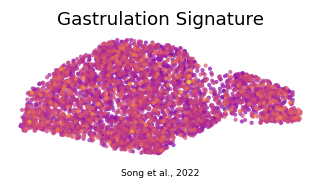

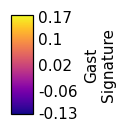

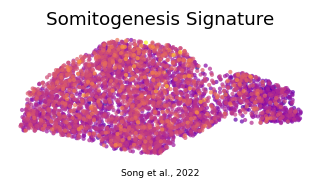

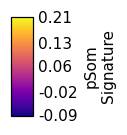

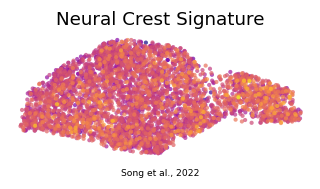

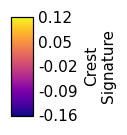

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Song et al., 2022', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (4574, 17235)
